       FUZZY WASHING MACHINE CONTROLLER
Dirt Level   : 8/10
Fabric Type  : 8/10
Washing Time : 27.41 minutes


C:\Users\gupta\AppData\Local\Programs\Python\Python313\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


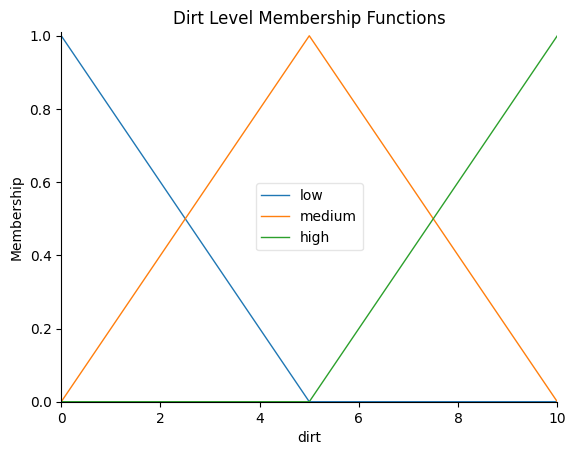

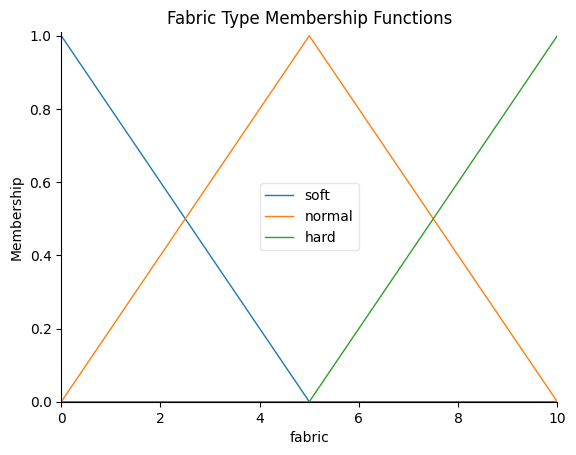

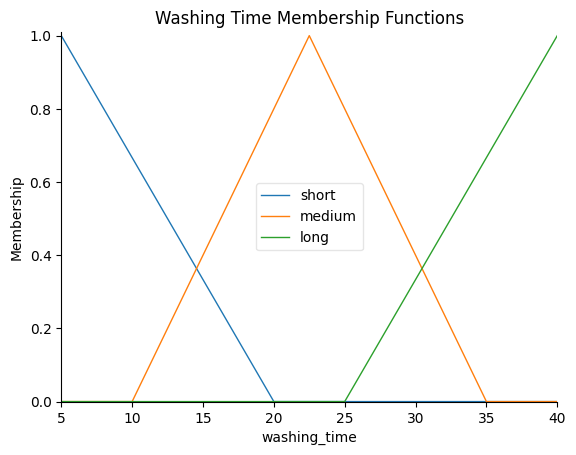

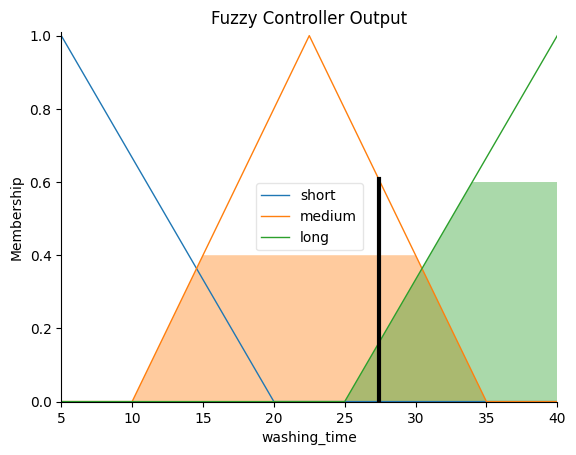

In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# FUZZY CONTROLLER FOR WASHING MACHINE
# Inputs  : Dirt Level, Fabric Type
# Output  : Washing Time
# STEP 1: Define input and output variables

dirt = ctrl.Antecedent(np.arange(0, 10.1, 0.1),
'dirt')
fabric = ctrl.Antecedent(np.arange(0, 10.1, 0.1),
'fabric')
washing_time = ctrl.Consequent(
    np.arange(5, 40.1, 0.1),
    'washing_time'
)

# ------------------------------------------------------------
# STEP 2: Define membership functions for DIRT
# ------------------------------------------------------------

dirt['low'] = fuzz.trimf(dirt.universe, [0, 0, 5])
dirt['medium'] = fuzz.trimf(dirt.universe, [0, 5,
10])
dirt['high'] = fuzz.trimf(dirt.universe, [5, 10, 10])

# ------------------------------------------------------------
# STEP 3: Define membership functions for FABRIC
# ------------------------------------------------------------

fabric['soft'] = fuzz.trimf(fabric.universe, [0, 0, 5])
fabric['normal'] = fuzz.trimf(fabric.universe, [0, 5,
10])
fabric['hard'] = fuzz.trimf(fabric.universe, [5, 10,
10])

# ------------------------------------------------------------
# STEP 4: Define membership functions for WASHING TIME
# ------------------------------------------------------------

washing_time['short'] = fuzz.trimf(
    washing_time.universe,
    [5, 5, 20]
)

washing_time['medium'] = fuzz.trimf(
    washing_time.universe,
    [10, 22.5, 35]
)

washing_time['long'] = fuzz.trimf(
    washing_time.universe,
    [25, 40, 40]
)

# ------------------------------------------------------------
# STEP 5: Define fuzzy rules
# ------------------------------------------------------------

rule1 = ctrl.Rule(
    dirt['low'] & fabric['soft'],
    washing_time['short']
)

rule2 = ctrl.Rule(
    dirt['low'] & fabric['normal'],
    washing_time['short']
)

rule3 = ctrl.Rule(
    dirt['low'] & fabric['hard'],
    washing_time['medium']
)

rule4 = ctrl.Rule(
    dirt['medium'] & fabric['soft'],
    washing_time['medium']
)

rule5 = ctrl.Rule(
    dirt['medium'] & fabric['normal'],
    washing_time['medium']
)




rule6 = ctrl.Rule(
    dirt['medium'] & fabric['hard'],
    washing_time['long']
)

rule7 = ctrl.Rule(
    dirt['high'] & fabric['soft'],
    washing_time['medium']
)

rule8 = ctrl.Rule(
    dirt['high'] & fabric['normal'],
    washing_time['long']
)

rule9 = ctrl.Rule(
    dirt['high'] & fabric['hard'],
    washing_time['long']
)

# ------------------------------------------------------------
# STEP 6: Create fuzzy control system
# ------------------------------------------------------------

washing_control = ctrl.ControlSystem([
    rule1,
    rule2,
    rule3,
    rule4,
    rule5,
    rule6,
    rule7,
    rule8,
    rule9
])

washing_machine = ctrl.ControlSystemSimulation(washing_control)


dirt_value = 8
fabric_value = 8

washing_machine.input['dirt'] = dirt_value
washing_machine.input['fabric'] = fabric_value

# ------------------------------------------------------------
# STEP 8: Perform fuzzy inference
# ------------------------------------------------------------

washing_machine.compute()

# ------------------------------------------------------------
# STEP 9: Display output
# ------------------------------------------------------------

result = washing_machine.output['washing_time']

print("=" * 50)
print("       FUZZY WASHING MACHINE CONTROLLER")
print("=" * 50)

print(f"Dirt Level   : {dirt_value}/10")
print(f"Fabric Type  : {fabric_value}/10")
print(f"Washing Time : {result:.2f} minutes")

print("=" * 50)

# ------------------------------------------------------------
# STEP 10: Display membership functions
# ------------------------------------------------------------

dirt.view()
plt.title("Dirt Level Membership Functions")
plt.show()

fabric.view()
plt.title("Fabric Type Membership Functions")
plt.show()

washing_time.view()
plt.title("Washing Time Membership Functions")
plt.show()



washing_time.view(sim=washing_machine)
plt.title("Fuzzy Controller Output")
plt.show()